1. cài đặt thư viện

In [1]:
!pip install -q -U \
    "transformers>=4.57,<5" \
    "trl==0.29.0" \
    "peft>=0.17,<1" \
    "accelerate>=1.10,<2" \
    "bitsandbytes>=0.47,<1" \
    "datasets>=4.1,<5" \
    sentencepiece

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 854.6 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 528.8/528.8 kB 21.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 100.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 54.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 21.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 8.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 45.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.29.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


2. Kết nối Google Drive

In [2]:
from google.colab import drive
drive.mount("/content/drive")

import torch
import platform

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("CUDA khả dụng:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError(
        "Chưa có GPU. Hãy chọn "
        "Runtime → Change runtime type → T4 GPU."
    )

gpu_name = torch.cuda.get_device_name(0)

gpu_memory = (
    torch.cuda.get_device_properties(0).total_memory
    / 1024**3
)

print("GPU:", gpu_name)
print("VRAM:", round(gpu_memory, 2), "GB")

!nvidia-smi

Mounted at /content/drive
Python: 3.13.15
PyTorch: 2.11.0+cu130
CUDA khả dụng: True
GPU: Tesla T4
VRAM: 14.56 GB
Mon Oct 12 13:55:14 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   52C    P8             10W /   70W |       3MiB /  15360MiB |      0%      Default |
|                          

3. cấu hình

In [3]:
from pathlib import Path

import math


# ============================================================
# 1. ĐƯỜNG DẪN DỰ ÁN
# ============================================================

PROJECT_DIR = Path(
    "/content/drive/MyDrive/ViGovBot_KLCN_2026"
)

DATA_ROOT = PROJECT_DIR / "data"

TEST_CASE_DIR = (
    DATA_ROOT
    / "qa_test"
    / "tthc_test_case_v1"
)

FINETUNING_DATA_DIR = (
    TEST_CASE_DIR
    / "data"
    / "fintuning"
)


# ============================================================
# 2. DỮ LIỆU
# ============================================================

TRAIN_FILE = (
    FINETUNING_DATA_DIR
    / "train_sft.jsonl"
)

VALIDATION_FILE = (
    FINETUNING_DATA_DIR
    / "validation_sft.jsonl"
)

TEST_FILE = (
    FINETUNING_DATA_DIR
    / "test_sft.jsonl"
)


# ============================================================
# 3. TÊN THỰC NGHIỆM MỚI
# ============================================================

RUN_NAME = (
    "qwen2_5_7b_qlora_"
    "200samples_earlystop_p5"
)


# ============================================================
# 4. THƯ MỤC KẾT QUẢ MỚI
# ============================================================

OUTPUT_ROOT = (
    TEST_CASE_DIR
    / "results"
    / RUN_NAME
)

ADAPTER_DIR = OUTPUT_ROOT / "adapter"
CHECKPOINT_DIR = OUTPUT_ROOT / "checkpoints"
EVALUATION_DIR = OUTPUT_ROOT / "evaluation"
FIGURES_DIR = OUTPUT_ROOT / "figures"

TRAIN_SUBSET_MANIFEST_PATH = (
    OUTPUT_ROOT
    / "train_subset_200_manifest.json"
)

QLORA_PARAMETER_STATS_PATH = (
    EVALUATION_DIR
    / "qlora_parameter_efficiency.json"
)

QLORA_PARAMETER_TABLE_PATH = (
    EVALUATION_DIR
    / "qlora_parameter_efficiency.csv"
)

TRAINING_COMPLETE_PATH = (
    OUTPUT_ROOT
    / "training_complete.json"
)


for directory in [
    OUTPUT_ROOT,
    ADAPTER_DIR,
    CHECKPOINT_DIR,
    EVALUATION_DIR,
    FIGURES_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ============================================================
# 5. CẤU HÌNH MÔ HÌNH
# ============================================================

MODEL_NAME = (
    "Qwen/Qwen2.5-7B-Instruct"
)

MODEL_REVISION = "main"

SEED = 42
MAX_LENGTH = 1024


# ============================================================
# 6. THỰC NGHIỆM 200 CÂU
# ============================================================

TRAIN_SAMPLE_COUNT = 200

# Giới hạn tối đa; có thể dừng sớm.
NUM_EPOCHS = 20

PER_DEVICE_TRAIN_BATCH_SIZE = 1
PER_DEVICE_EVAL_BATCH_SIZE = 1
GRADIENT_ACCUMULATION_STEPS = 8

EFFECTIVE_BATCH_SIZE = (
    PER_DEVICE_TRAIN_BATCH_SIZE
    * GRADIENT_ACCUMULATION_STEPS
)

STEPS_PER_EPOCH = math.ceil(
    TRAIN_SAMPLE_COUNT
    / EFFECTIVE_BATCH_SIZE
)

# 200 / 8 = 25 step/epoch
LOGGING_STEPS = 5
EVAL_STEPS = STEPS_PER_EPOCH
SAVE_STEPS = STEPS_PER_EPOCH

EARLY_STOPPING_PATIENCE = 5
EARLY_STOPPING_THRESHOLD = 0.0


print("===== CẤU HÌNH THỰC NGHIỆM =====")
print("Run name:", RUN_NAME)
print("Train gốc:", TRAIN_FILE)
print("Validation:", VALIDATION_FILE)
print("Test:", TEST_FILE)
print("Số mẫu Train sử dụng:", TRAIN_SAMPLE_COUNT)
print("Epoch tối đa:", NUM_EPOCHS)
print("Batch hiệu dụng:", EFFECTIVE_BATCH_SIZE)
print("Step mỗi epoch:", STEPS_PER_EPOCH)
print(
    "Early Stopping:",
    EARLY_STOPPING_PATIENCE,
    "lần Validation không giảm",
)
print("Kết quả mới:", OUTPUT_ROOT)
print("Checkpoint:", CHECKPOINT_DIR)

===== CẤU HÌNH THỰC NGHIỆM =====
Run name: qwen2_5_7b_qlora_200samples_earlystop_p5
Train gốc: /content/drive/MyDrive/ViGovBot_KLCN_2026/data/qa_test/tthc_test_case_v1/data/fintuning/train_sft.jsonl
Validation: /content/drive/MyDrive/ViGovBot_KLCN_2026/data/qa_test/tthc_test_case_v1/data/fintuning/validation_sft.jsonl
Test: /content/drive/MyDrive/ViGovBot_KLCN_2026/data/qa_test/tthc_test_case_v1/data/fintuning/test_sft.jsonl
Số mẫu Train sử dụng: 200
Epoch tối đa: 20
Batch hiệu dụng: 8
Step mỗi epoch: 25
Early Stopping: 5 lần Validation không giảm
Kết quả mới: /content/drive/MyDrive/ViGovBot_KLCN_2026/data/qa_test/tthc_test_case_v1/results/qwen2_5_7b_qlora_200samples_earlystop_p5
Checkpoint: /content/drive/MyDrive/ViGovBot_KLCN_2026/data/qa_test/tthc_test_case_v1/results/qwen2_5_7b_qlora_200samples_earlystop_p5/checkpoints


4. kiểm tra

In [4]:
required_files = {
    "Train": TRAIN_FILE,
    "Validation": VALIDATION_FILE,
    "Test": TEST_FILE,
}

print("===== KIỂM TRA FILE DỮ LIỆU =====")

for split_name, file_path in required_files.items():
    print(f"\n{split_name}:")
    print(file_path)

    if not file_path.exists():
        raise FileNotFoundError(
            f"Không tìm thấy file {split_name}: {file_path}"
        )

    file_size_mb = (
        file_path.stat().st_size
        / 1024**2
    )

    print("Trạng thái: Đã tìm thấy")
    print(f"Kích thước: {file_size_mb:.2f} MB")

print("\nĐã tìm thấy đầy đủ ba tập dữ liệu.")

===== KIỂM TRA FILE DỮ LIỆU =====

Train:
/content/drive/MyDrive/ViGovBot_KLCN_2026/data/qa_test/tthc_test_case_v1/data/fintuning/train_sft.jsonl
Trạng thái: Đã tìm thấy
Kích thước: 3.22 MB

Validation:
/content/drive/MyDrive/ViGovBot_KLCN_2026/data/qa_test/tthc_test_case_v1/data/fintuning/validation_sft.jsonl
Trạng thái: Đã tìm thấy
Kích thước: 1.06 MB

Test:
/content/drive/MyDrive/ViGovBot_KLCN_2026/data/qa_test/tthc_test_case_v1/data/fintuning/test_sft.jsonl
Trạng thái: Đã tìm thấy
Kích thước: 1.06 MB

Đã tìm thấy đầy đủ ba tập dữ liệu.


5. Đọc dữ liệu pilot

In [5]:
import hashlib
import json

from datasets import (
    DatasetDict,
    load_dataset,
)


def load_sft_split(
    file_path,
    split_name,
):
    dataset = load_dataset(
        "json",
        data_files=str(file_path),
        split="train",
    )

    required_columns = {
        "id",
        "messages",
    }

    missing_columns = (
        required_columns
        - set(dataset.column_names)
    )

    if missing_columns:
        raise ValueError(
            f"{split_name} thiếu các cột: "
            f"{sorted(missing_columns)}"
        )

    extra_columns = [
        column
        for column in dataset.column_names
        if column not in required_columns
    ]

    if extra_columns:
        dataset = dataset.remove_columns(
            extra_columns
        )

    print(f"\n{split_name}:")
    print("- Số mẫu:", len(dataset))
    print("- Các cột:", dataset.column_names)

    return dataset


# ============================================================
# 1. ĐỌC TOÀN BỘ DỮ LIỆU
# ============================================================

train_full = load_sft_split(
    TRAIN_FILE,
    "Train gốc",
)

validation_raw = load_sft_split(
    VALIDATION_FILE,
    "Validation",
)

test_raw = load_sft_split(
    TEST_FILE,
    "Test",
)

FULL_TRAIN_EXAMPLES = len(
    train_full
)

if FULL_TRAIN_EXAMPLES < TRAIN_SAMPLE_COUNT:
    raise ValueError(
        "Tập Train không đủ "
        f"{TRAIN_SAMPLE_COUNT} mẫu."
    )


# ============================================================
# 2. KIỂM TRA ID TRAIN
# ============================================================

all_train_ids = list(
    train_full["id"]
)

if len(all_train_ids) != len(
    set(all_train_ids)
):
    raise ValueError(
        "Tập Train gốc có ID trùng."
    )

id_to_index = {
    example_id: index
    for index, example_id
    in enumerate(all_train_ids)
}


# ============================================================
# 3. TẠO HOẶC ĐỌC DANH SÁCH 200 ID
# ============================================================

if TRAIN_SUBSET_MANIFEST_PATH.exists():
    print(
        "\nĐang sử dụng lại danh sách "
        "200 câu Train đã lưu."
    )

    with TRAIN_SUBSET_MANIFEST_PATH.open(
        "r",
        encoding="utf-8",
    ) as file:
        subset_manifest = json.load(
            file
        )

    if (
        subset_manifest[
            "sample_count"
        ]
        != TRAIN_SAMPLE_COUNT
    ):
        raise ValueError(
            "Manifest cũ không trùng "
            "TRAIN_SAMPLE_COUNT."
        )

    if subset_manifest["seed"] != SEED:
        raise ValueError(
            "Manifest cũ không trùng SEED."
        )

    selected_train_ids = (
        subset_manifest[
            "selected_ids"
        ]
    )

else:
    print(
        "\nĐang chọn cố định "
        f"{TRAIN_SAMPLE_COUNT} câu Train..."
    )

    shuffled_train = (
        train_full.shuffle(
            seed=SEED
        )
    )

    selected_train_ids = list(
        shuffled_train[
            "id"
        ][:TRAIN_SAMPLE_COUNT]
    )

    subset_hash = hashlib.sha256(
        json.dumps(
            selected_train_ids,
            ensure_ascii=False,
        ).encode("utf-8")
    ).hexdigest()

    subset_manifest = {
        "source_file": str(
            TRAIN_FILE
        ),
        "source_examples": (
            FULL_TRAIN_EXAMPLES
        ),
        "sample_count": (
            TRAIN_SAMPLE_COUNT
        ),
        "seed": SEED,
        "selected_ids_sha256": (
            subset_hash
        ),
        "selected_ids": (
            selected_train_ids
        ),
    }

    with TRAIN_SUBSET_MANIFEST_PATH.open(
        "w",
        encoding="utf-8",
    ) as file:
        json.dump(
            subset_manifest,
            file,
            ensure_ascii=False,
            indent=2,
        )


# ============================================================
# 4. KIỂM TRA MANIFEST
# ============================================================

missing_selected_ids = [
    example_id
    for example_id in selected_train_ids
    if example_id not in id_to_index
]

if missing_selected_ids:
    raise ValueError(
        "Một số ID trong manifest "
        "không còn tồn tại trong Train."
    )

TRAIN_SUBSET_HASH = hashlib.sha256(
    json.dumps(
        selected_train_ids,
        ensure_ascii=False,
    ).encode("utf-8")
).hexdigest()

manifest_hash = subset_manifest.get(
    "selected_ids_sha256"
)

if (
    manifest_hash
    and manifest_hash
    != TRAIN_SUBSET_HASH
):
    raise ValueError(
        "Hash danh sách Train không khớp."
    )


# ============================================================
# 5. TẠO TẬP TRAIN 200 CÂU
# ============================================================

selected_indices = [
    id_to_index[example_id]
    for example_id
    in selected_train_ids
]

train_raw = train_full.select(
    selected_indices
)


raw_datasets = DatasetDict({
    "train": train_raw,
    "validation": validation_raw,
    "test": test_raw,
})


print("\n===== DATASET THỰC NGHIỆM =====")
print(raw_datasets)

print(
    "Train gốc:",
    FULL_TRAIN_EXAMPLES,
)

print(
    "Train sử dụng:",
    len(raw_datasets["train"]),
)

print(
    "Validation:",
    len(raw_datasets["validation"]),
)

print(
    "Test:",
    len(raw_datasets["test"]),
)

print(
    "Subset hash:",
    TRAIN_SUBSET_HASH,
)

print(
    "Manifest:",
    TRAIN_SUBSET_MANIFEST_PATH,
)

print("\nMột mẫu Train:")
print(raw_datasets["train"][0])

Generating train split: 0 examples [00:00, ? examples/s]


Train gốc:
- Số mẫu: 3000
- Các cột: ['id', 'messages']


Generating train split: 0 examples [00:00, ? examples/s]


Validation:
- Số mẫu: 1000
- Các cột: ['id', 'messages']


Generating train split: 0 examples [00:00, ? examples/s]


Test:
- Số mẫu: 1000
- Các cột: ['id', 'messages']

Đang sử dụng lại danh sách 200 câu Train đã lưu.

===== DATASET THỰC NGHIỆM =====
DatasetDict({
    train: Dataset({
        features: ['id', 'messages'],
        num_rows: 200
    })
    validation: Dataset({
        features: ['id', 'messages'],
        num_rows: 1000
    })
    test: Dataset({
        features: ['id', 'messages'],
        num_rows: 1000
    })
})
Train gốc: 3000
Train sử dụng: 200
Validation: 1000
Test: 1000
Subset hash: 834c9dfd087ed45d936b3df4289a51749e333cdb52544c55bf278f9fa663e19f
Manifest: /content/drive/MyDrive/ViGovBot_KLCN_2026/data/qa_test/tthc_test_case_v1/results/qwen2_5_7b_qlora_200samples_earlystop_p5/train_subset_200_manifest.json

Một mẫu Train:
{'id': 'qa2_03923', 'messages': [{'role': 'user', 'content': 'Đối với “Phê duyệt lựa chọn dự án Vùng trồng dược liệu quý trên địa bàn hai huyện trở lên thuộc thẩm quyền quyết định của Ủy ban nhân dân tỉnh” (mã 1.014484), Tôi cho rằng mục “Miễn phí” ghi “Khôn

6. Kiểm tra cấu trúc dữ liệu

In [6]:
import json


def validate_sft_example(example):
    example_id = example.get("id")
    messages = example.get("messages")

    if not isinstance(example_id, str):
        return False

    if not example_id.strip():
        return False

    if not isinstance(messages, list):
        return False

    # Mỗi cuộc hội thoại phải có số message chẵn:
    # user → assistant hoặc
    # user → assistant → user → assistant
    if len(messages) < 2:
        return False

    if len(messages) % 2 != 0:
        return False

    expected_roles = (
        ["user", "assistant"]
        * (len(messages) // 2)
    )

    actual_roles = []

    for message in messages:
        if not isinstance(message, dict):
            return False

        role = message.get("role")
        content = message.get("content")

        if role not in {
            "user",
            "assistant",
        }:
            return False

        if not isinstance(content, str):
            return False

        if not content.strip():
            return False

        actual_roles.append(role)

    if actual_roles != expected_roles:
        return False

    return True


# ============================================================
# KIỂM TRA TỪNG SPLIT
# ============================================================

for split_name in [
    "train",
    "validation",
    "test",
]:
    invalid_ids = [
        example.get("id", "unknown")
        for example in raw_datasets[split_name]
        if not validate_sft_example(example)
    ]

    print(
        f"{split_name}: "
        f"{len(invalid_ids)} mẫu không hợp lệ"
    )

    if invalid_ids:
        print("Một số ID lỗi:", invalid_ids[:10])

        raise ValueError(
            f"Tập {split_name} có dữ liệu không hợp lệ."
        )


# ============================================================
# KIỂM TRA ID TRÙNG TRONG TỪNG SPLIT
# ============================================================

split_ids = {}

for split_name in [
    "train",
    "validation",
    "test",
]:
    ids = [
        example["id"]
        for example in raw_datasets[split_name]
    ]

    split_ids[split_name] = set(ids)

    if len(ids) != len(set(ids)):
        raise ValueError(
            f"Tập {split_name} có ID bị trùng."
        )


# ============================================================
# KIỂM TRA ID GIỮA CÁC SPLIT
# ============================================================

train_validation_overlap = (
    split_ids["train"]
    & split_ids["validation"]
)

train_test_overlap = (
    split_ids["train"]
    & split_ids["test"]
)

validation_test_overlap = (
    split_ids["validation"]
    & split_ids["test"]
)

print("\n===== KIỂM TRA ID GIAO NHAU =====")
print(
    "Train ∩ Validation:",
    len(train_validation_overlap),
)
print(
    "Train ∩ Test:",
    len(train_test_overlap),
)
print(
    "Validation ∩ Test:",
    len(validation_test_overlap),
)

if (
    train_validation_overlap
    or train_test_overlap
    or validation_test_overlap
):
    raise ValueError(
        "ID giữa các tập dữ liệu đang bị trùng."
    )


# ============================================================
# KIỂM TRA PROMPT TRÙNG HOÀN TOÀN
# ============================================================

def prompt_signature(example):
    # Không đưa đáp án assistant cuối cùng vào prompt
    prompt_messages = example["messages"][:-1]

    return json.dumps(
        prompt_messages,
        ensure_ascii=False,
        sort_keys=True,
    )


prompt_sets = {}

for split_name in [
    "train",
    "validation",
    "test",
]:
    prompt_sets[split_name] = {
        prompt_signature(example)
        for example in raw_datasets[split_name]
    }


print("\n===== KIỂM TRA PROMPT TRÙNG =====")

print(
    "Train ∩ Validation:",
    len(
        prompt_sets["train"]
        & prompt_sets["validation"]
    ),
)

print(
    "Train ∩ Test:",
    len(
        prompt_sets["train"]
        & prompt_sets["test"]
    ),
)

print(
    "Validation ∩ Test:",
    len(
        prompt_sets["validation"]
        & prompt_sets["test"]
    ),
)

print("\nToàn bộ dữ liệu hợp lệ.")

train: 0 mẫu không hợp lệ
validation: 0 mẫu không hợp lệ
test: 0 mẫu không hợp lệ

===== KIỂM TRA ID GIAO NHAU =====
Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0

===== KIỂM TRA PROMPT TRÙNG =====
Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0

Toàn bộ dữ liệu hợp lệ.


6A. vẽ biểu đồ train


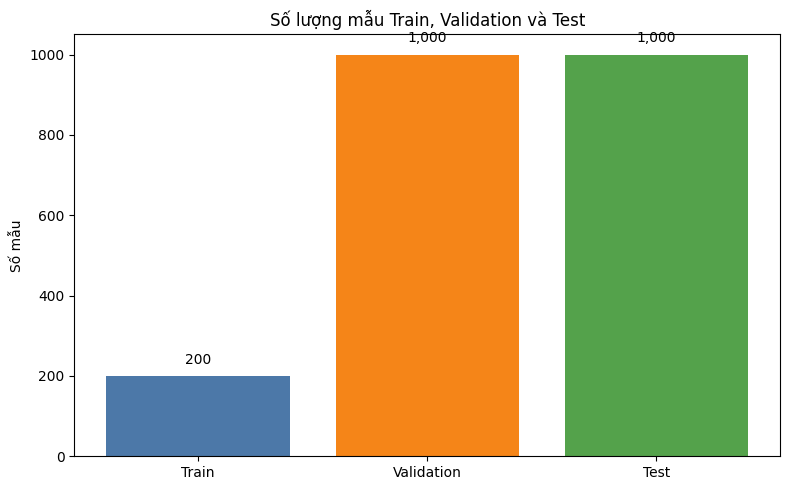

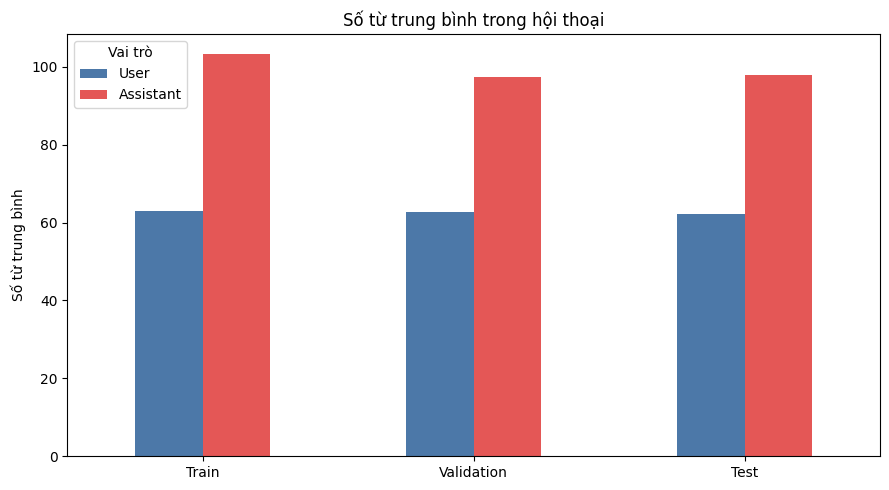

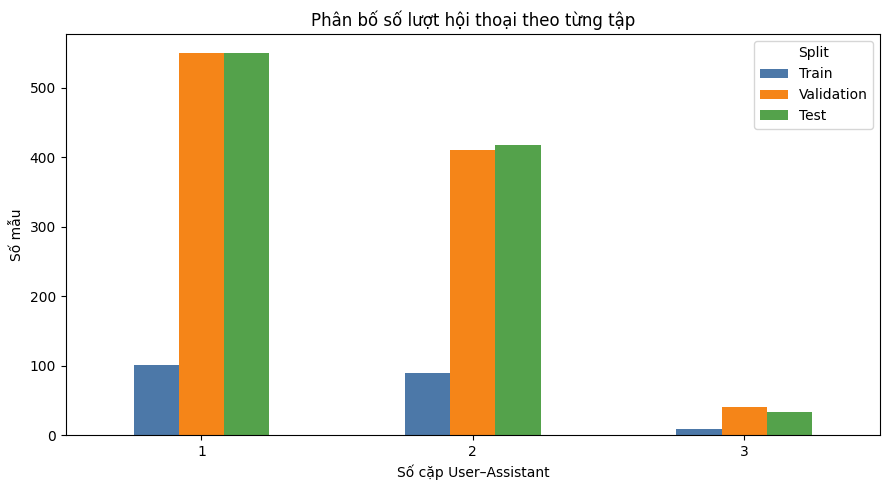

Đã lưu ba biểu đồ tại:
/content/drive/MyDrive/ViGovBot_KLCN_2026/data/qa_test/tthc_test_case_v1/results/qwen2_5_7b_qlora_200samples_earlystop_p5/figures


In [7]:
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd


# ============================================================
# HÀM THỐNG KÊ
# ============================================================

def count_words_by_role(
    example,
    target_role,
):
    contents = [
        message["content"]
        for message in example["messages"]
        if message["role"] == target_role
    ]

    return sum(
        len(content.split())
        for content in contents
    )


split_names = [
    "train",
    "validation",
    "test",
]

display_names = [
    "Train",
    "Validation",
    "Test",
]

colors = [
    "#4C78A8",
    "#F58518",
    "#54A24B",
]


# ============================================================
# BIỂU ĐỒ 1: SỐ LƯỢNG MẪU
# ============================================================

sample_counts = [
    len(raw_datasets[split_name])
    for split_name in split_names
]

plt.figure(figsize=(8, 5))

bars = plt.bar(
    display_names,
    sample_counts,
    color=colors,
)

for bar, value in zip(
    bars,
    sample_counts,
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 30,
        f"{value:,}",
        ha="center",
    )

plt.title(
    "Số lượng mẫu Train, Validation và Test"
)
plt.ylabel("Số mẫu")
plt.tight_layout()

split_count_chart = (
    FIGURES_DIR
    / "01_split_sample_counts.png"
)

plt.savefig(
    split_count_chart,
    dpi=300,
    bbox_inches="tight",
)

plt.show()


# ============================================================
# BIỂU ĐỒ 2: ĐỘ DÀI TRUNG BÌNH
# ============================================================

length_rows = []

for split_name, display_name in zip(
    split_names,
    display_names,
):
    dataset = raw_datasets[split_name]

    user_words = [
        count_words_by_role(
            example,
            "user",
        )
        for example in dataset
    ]

    assistant_words = [
        count_words_by_role(
            example,
            "assistant",
        )
        for example in dataset
    ]

    length_rows.append({
        "Split": display_name,
        "User": sum(user_words) / len(user_words),
        "Assistant": (
            sum(assistant_words)
            / len(assistant_words)
        ),
    })


length_df = pd.DataFrame(length_rows)
length_df = length_df.set_index("Split")

length_df.plot(
    kind="bar",
    figsize=(9, 5),
    color=[
        "#4C78A8",
        "#E45756",
    ],
)

plt.title(
    "Số từ trung bình trong hội thoại"
)
plt.ylabel("Số từ trung bình")
plt.xlabel("")
plt.xticks(rotation=0)
plt.legend(title="Vai trò")
plt.tight_layout()

average_length_chart = (
    FIGURES_DIR
    / "02_average_words_by_role.png"
)

plt.savefig(
    average_length_chart,
    dpi=300,
    bbox_inches="tight",
)

plt.show()


# ============================================================
# BIỂU ĐỒ 3: SỐ LƯỢT HỘI THOẠI
# ============================================================

turn_rows = []

for split_name, display_name in zip(
    split_names,
    display_names,
):
    turn_counter = Counter(
        len(example["messages"]) // 2
        for example in raw_datasets[split_name]
    )

    for turns, count in sorted(
        turn_counter.items()
    ):
        turn_rows.append({
            "Split": display_name,
            "Số lượt hội thoại": turns,
            "Số mẫu": count,
        })


turn_df = pd.DataFrame(turn_rows)

turn_pivot = turn_df.pivot(
    index="Số lượt hội thoại",
    columns="Split",
    values="Số mẫu",
).fillna(0)

turn_pivot = turn_pivot[
    display_names
]

turn_pivot.plot(
    kind="bar",
    figsize=(9, 5),
    color=colors,
)

plt.title(
    "Phân bố số lượt hội thoại theo từng tập"
)
plt.ylabel("Số mẫu")
plt.xlabel("Số cặp User–Assistant")
plt.xticks(rotation=0)
plt.tight_layout()

conversation_turn_chart = (
    FIGURES_DIR
    / "03_conversation_turn_distribution.png"
)

plt.savefig(
    conversation_turn_chart,
    dpi=300,
    bbox_inches="tight",
)

plt.show()


print("Đã lưu ba biểu đồ tại:")
print(FIGURES_DIR)

7. Chuyển dữ liệu thành hội thoại Fine-tuning

In [8]:
def to_prompt_completion(example):
    messages = example["messages"]

    # Assistant cuối cùng là câu trả lời cần học
    assistant_message = messages[-1]

    # Toàn bộ hội thoại trước đó là đầu vào
    prompt_messages = messages[:-1]

    return {
        "id": example["id"],
        "prompt": prompt_messages,
        "completion": [
            assistant_message
        ],
    }


train_dataset = raw_datasets["train"].map(
    to_prompt_completion,
    remove_columns=(
        raw_datasets["train"].column_names
    ),
    desc="Chuyển đổi Train",
)

validation_dataset = (
    raw_datasets["validation"].map(
        to_prompt_completion,
        remove_columns=(
            raw_datasets[
                "validation"
            ].column_names
        ),
        desc="Chuyển đổi Validation",
    )
)


print("===== DỮ LIỆU SAU CHUYỂN ĐỔI =====")

print(
    "Train:",
    len(train_dataset),
)

print(
    "Validation:",
    len(validation_dataset),
)

print("\nCác cột:")
print(train_dataset.column_names)

print("\nPrompt mẫu:")
print(train_dataset[0]["prompt"])

print("\nCompletion mẫu:")
print(train_dataset[0]["completion"])

assert (
    train_dataset[0]["completion"][0]["role"]
    == "assistant"
)

print("\nChuyển đổi thành công.")

Chuyển đổi Train:   0%|          | 0/200 [00:00<?, ? examples/s]

Chuyển đổi Validation:   0%|          | 0/1000 [00:00<?, ? examples/s]

===== DỮ LIỆU SAU CHUYỂN ĐỔI =====
Train: 200
Validation: 1000

Các cột:
['id', 'prompt', 'completion']

Prompt mẫu:
[{'content': 'Đối với “Phê duyệt lựa chọn dự án Vùng trồng dược liệu quý trên địa bàn hai huyện trở lên thuộc thẩm quyền quyết định của Ủy ban nhân dân tỉnh” (mã 1.014484), Tôi cho rằng mục “Miễn phí” ghi “Không áp dụng”. Có đúng không? Hãy đối chiếu và sửa lại theo tài liệu.', 'role': 'user'}]

Completion mẫu:
[{'content': 'Tiền đề trên không đúng với tài liệu. Miễn phí (khi nộp bằng hình thức Trực tuyến): Miễn phí', 'role': 'assistant'}]

Chuyển đổi thành công.


8. Nạp Qwen2.5-7B ở chế độ 4-bit

In [9]:
import torch

from transformers import (
    AutoModelForCausalLM,
    AutoTokenizer,
    BitsAndBytesConfig,
)

from peft import (
    prepare_model_for_kbit_training,
)

USE_BF16 = torch.cuda.is_bf16_supported()

COMPUTE_DTYPE = (
    torch.bfloat16
    if USE_BF16
    else torch.float16
)

print("Kiểu tính toán:", COMPUTE_DTYPE)

quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,

    # NormalFloat 4 dùng cho QLoRA
    bnb_4bit_quant_type="nf4",

    # Giảm thêm bộ nhớ GPU
    bnb_4bit_use_double_quant=True,

    bnb_4bit_compute_dtype=COMPUTE_DTYPE,
)

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    revision=MODEL_REVISION,
    use_fast=True,
)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

tokenizer.padding_side = "right"

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    revision=MODEL_REVISION,
    quantization_config=quantization_config,
    device_map={"": 0},
    torch_dtype=COMPUTE_DTYPE,
    low_cpu_mem_usage=True,
)

model.config.use_cache = False

model = prepare_model_for_kbit_training(
    model,
    use_gradient_checkpointing=True,
)

print("\nĐã nạp mô hình:", MODEL_NAME)
print(
    "Thiết bị:",
    next(model.parameters()).device
)

Kiểu tính toán: torch.bfloat16


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

...

model-00002-of-00004.safetensors:   0%|          | 0.00/3.86G [00:00<?, ?B/s]

model-00001-of-00004.safetensors:   0%|          | 0.00/3.95G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]


Đã nạp mô hình: Qwen/Qwen2.5-7B-Instruct
Thiết bị: cuda:0


9. Gắn QLoRA adapter

In [10]:
# ============================================================
# CELL 9 – GẮN QLORA ADAPTER
# VÀ THỐNG KÊ HIỆU QUẢ THAM SỐ
# ============================================================

import json

import pandas as pd

from peft import (
    LoraConfig,
    get_peft_model,
)


# ============================================================
# 1. CẤU HÌNH LORA
# ============================================================

lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",

    target_modules=[
        "q_proj",
        "k_proj",
        "v_proj",
        "o_proj",
        "gate_proj",
        "up_proj",
        "down_proj",
    ],
)


# ============================================================
# 2. GẮN LORA ADAPTER VÀO BASE MODEL 4-BIT
# ============================================================

model = get_peft_model(
    model,
    lora_config,
)


# ============================================================
# 3. ĐẾM THAM SỐ
# ============================================================

(
    trainable_parameters,
    total_parameters,
) = model.get_nb_trainable_parameters()


# Tổng tham số Base bị đóng băng.
# Vì total_parameters bao gồm cả Base và LoRA Adapter.
frozen_parameters = (
    total_parameters
    - trainable_parameters
)


# Số tham số của Base model được dùng làm mốc
# so sánh với Full Fine-tuning.
base_model_parameters = (
    frozen_parameters
)


# Khi dùng QLoRA, toàn bộ tham số Base không được cập nhật.
parameters_not_updated = (
    frozen_parameters
)


# Tỷ lệ tham số thực sự được huấn luyện
# trên tổng Base + Adapter.
trainable_percentage = (
    trainable_parameters
    / total_parameters
    * 100
)


# So sánh số tham số QLoRA cần cập nhật
# với số tham số cần cập nhật nếu Full Fine-tuning.
parameter_reduction_percentage = (
    1
    - (
        trainable_parameters
        / base_model_parameters
    )
) * 100


# Full Fine-tuning cần cập nhật nhiều hơn
# QLoRA bao nhiêu lần.
parameter_reduction_factor = (
    base_model_parameters
    / trainable_parameters
)


# ============================================================
# 4. ƯỚC TÍNH BỘ NHỚ TRỌNG SỐ
# ============================================================

BYTES_PER_GIB = 1024**3
BYTES_PER_MIB = 1024**2


# Nếu Base model được lưu bằng FP16:
# mỗi tham số khoảng 2 byte.
fp16_base_weight_gib = (
    base_model_parameters
    * 2
    / BYTES_PER_GIB
)


# Lượng tử hóa 4-bit:
# mỗi tham số lý thuyết khoảng 0.5 byte.
int4_base_weight_gib = (
    base_model_parameters
    * 0.5
    / BYTES_PER_GIB
)


# Mức giảm dung lượng trọng số lý thuyết
# khi chuyển từ FP16 sang 4-bit.
theoretical_weight_memory_reduction = (
    1
    - (
        int4_base_weight_gib
        / fp16_base_weight_gib
    )
) * 100


# Kích thước lý thuyết của Adapter nếu lưu FP16.
adapter_fp16_mib = (
    trainable_parameters
    * 2
    / BYTES_PER_MIB
)


# Kích thước lý thuyết nếu Adapter lưu FP32.
adapter_fp32_mib = (
    trainable_parameters
    * 4
    / BYTES_PER_MIB
)


# ============================================================
# 5. TẠO THỐNG KÊ QLORA
# ============================================================

QLORA_PARAMETER_STATS = {
    "base_model": MODEL_NAME,

    "total_parameters_including_adapter": int(
        total_parameters
    ),

    "base_model_parameters": int(
        base_model_parameters
    ),

    "base_frozen_parameters": int(
        frozen_parameters
    ),

    "trainable_lora_parameters": int(
        trainable_parameters
    ),

    "parameters_not_updated": int(
        parameters_not_updated
    ),

    "trainable_percentage": float(
        trainable_percentage
    ),

    "parameter_reduction_percentage": float(
        parameter_reduction_percentage
    ),

    "parameter_reduction_factor": float(
        parameter_reduction_factor
    ),

    "fp16_base_weight_gib_theoretical": float(
        fp16_base_weight_gib
    ),

    "int4_base_weight_gib_theoretical": float(
        int4_base_weight_gib
    ),

    "weight_memory_reduction_percentage_theoretical": float(
        theoretical_weight_memory_reduction
    ),

    "adapter_fp16_mib_theoretical": float(
        adapter_fp16_mib
    ),

    "adapter_fp32_mib_theoretical": float(
        adapter_fp32_mib
    ),

    "quantization": "NF4 4-bit",

    "double_quantization": True,

    "lora_r": 16,
    "lora_alpha": 32,
    "lora_dropout": 0.05,

    "target_modules": [
        "q_proj",
        "k_proj",
        "v_proj",
        "o_proj",
        "gate_proj",
        "up_proj",
        "down_proj",
    ],
}


# ============================================================
# 6. LƯU KẾT QUẢ DẠNG JSON
# ============================================================

QLORA_PARAMETER_STATS_PATH.parent.mkdir(
    parents=True,
    exist_ok=True,
)

with QLORA_PARAMETER_STATS_PATH.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        QLORA_PARAMETER_STATS,
        file,
        ensure_ascii=False,
        indent=2,
    )


# ============================================================
# 7. LƯU KẾT QUẢ DẠNG CSV
# ============================================================

pd.DataFrame([
    QLORA_PARAMETER_STATS
]).to_csv(
    QLORA_PARAMETER_TABLE_PATH,
    index=False,
    encoding="utf-8-sig",
)


# ============================================================
# 8. HIỂN THỊ KẾT QUẢ
# ============================================================

print("===== HIỆU QUẢ THAM SỐ QLORA =====")

print(
    "Tổng tham số Base + Adapter:",
    f"{total_parameters:,}",
)

print(
    "Tham số Base model:",
    f"{base_model_parameters:,}",
)

print(
    "Tham số QLoRA được huấn luyện:",
    f"{trainable_parameters:,}",
)

print(
    "Tham số Base bị đóng băng:",
    f"{frozen_parameters:,}",
)

print(
    "Tỷ lệ tham số được huấn luyện:",
    f"{trainable_percentage:.6f}%",
)

print(
    "Giảm số tham số cần cập nhật "
    "so với Full Fine-tuning:",
    f"{parameter_reduction_percentage:.4f}%",
)

print(
    "Số tham số cập nhật ít hơn "
    "Full Fine-tuning khoảng:",
    f"{parameter_reduction_factor:.2f} lần",
)

print(
    "Ước tính trọng số Base FP16:",
    f"{fp16_base_weight_gib:.2f} GiB",
)

print(
    "Ước tính trọng số Base 4-bit:",
    f"{int4_base_weight_gib:.2f} GiB",
)

print(
    "Mức giảm bộ nhớ trọng số lý thuyết:",
    f"{theoretical_weight_memory_reduction:.2f}%",
)

print(
    "Adapter FP16 lý thuyết:",
    f"{adapter_fp16_mib:.2f} MiB",
)

print(
    "Adapter FP32 lý thuyết:",
    f"{adapter_fp32_mib:.2f} MiB",
)


print("\n===== FILE ĐÃ LƯU =====")

print(
    "JSON:",
    QLORA_PARAMETER_STATS_PATH,
)

print(
    "CSV:",
    QLORA_PARAMETER_TABLE_PATH,
)


print("\n===== KIỂM TRA TỪ PEFT =====")

model.print_trainable_parameters()

===== HIỆU QUẢ THAM SỐ QLORA =====
Tổng tham số Base + Adapter: 7,655,986,688
Tham số Base model: 7,615,616,512
Tham số QLoRA được huấn luyện: 40,370,176
Tham số Base bị đóng băng: 7,615,616,512
Tỷ lệ tham số được huấn luyện: 0.527302%
Giảm số tham số cần cập nhật so với Full Fine-tuning: 99.4699%
Số tham số cập nhật ít hơn Full Fine-tuning khoảng: 188.64 lần
Ước tính trọng số Base FP16: 14.19 GiB
Ước tính trọng số Base 4-bit: 3.55 GiB
Mức giảm bộ nhớ trọng số lý thuyết: 75.00%
Adapter FP16 lý thuyết: 77.00 MiB
Adapter FP32 lý thuyết: 154.00 MiB

===== FILE ĐÃ LƯU =====
JSON: /content/drive/MyDrive/ViGovBot_KLCN_2026/data/qa_test/tthc_test_case_v1/results/qwen2_5_7b_qlora_200samples_earlystop_p5/evaluation/qlora_parameter_efficiency.json
CSV: /content/drive/MyDrive/ViGovBot_KLCN_2026/data/qa_test/tthc_test_case_v1/results/qwen2_5_7b_qlora_200samples_earlystop_p5/evaluation/qlora_parameter_efficiency.csv

===== KIỂM TRA TỪ PEFT =====
trainable params: 40,370,176 || all params: 7,655,986

10. Cấu hình quá trình Fine-tuning

In [11]:
from transformers import (
    EarlyStoppingCallback,
)

from trl import (
    SFTConfig,
    SFTTrainer,
)


training_args = SFTConfig(
    output_dir=str(
        CHECKPOINT_DIR
    ),

    # Tối đa 20 epoch
    num_train_epochs=NUM_EPOCHS,

    per_device_train_batch_size=(
        PER_DEVICE_TRAIN_BATCH_SIZE
    ),

    per_device_eval_batch_size=(
        PER_DEVICE_EVAL_BATCH_SIZE
    ),

    gradient_accumulation_steps=(
        GRADIENT_ACCUMULATION_STEPS
    ),

    learning_rate=2e-4,
    lr_scheduler_type="cosine",
    warmup_ratio=0.03,
    weight_decay=0.01,
    max_grad_norm=0.3,

    gradient_checkpointing=True,

    gradient_checkpointing_kwargs={
        "use_reentrant": False,
    },

    fp16=not USE_BF16,
    bf16=USE_BF16,

    optim="paged_adamw_8bit",

    max_length=MAX_LENGTH,
    packing=False,

    # Chỉ tính loss trên câu trả lời Assistant
    completion_only_loss=True,

    # 25 step tương ứng một epoch
    eval_strategy="steps",
    eval_steps=EVAL_STEPS,

    # Lưu checkpoint cùng lúc Validation
    save_strategy="steps",
    save_steps=SAVE_STEPS,
    save_total_limit=3,

    # Giữ optimizer và scheduler để resume
    save_only_model=False,

    # Tự nạp checkpoint có Val Loss thấp nhất
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,

    # Khôi phục trạng thái Early Stopping
    restore_callback_states_from_checkpoint=True,

    logging_strategy="steps",
    logging_steps=LOGGING_STEPS,
    logging_first_step=True,

    report_to="none",

    seed=SEED,
    data_seed=SEED,

    dataset_num_proc=2,
)


early_stopping_callback = (
    EarlyStoppingCallback(
        early_stopping_patience=(
            EARLY_STOPPING_PATIENCE
        ),
        early_stopping_threshold=(
            EARLY_STOPPING_THRESHOLD
        ),
    )
)


trainer = SFTTrainer(
    model=model,
    args=training_args,

    train_dataset=train_dataset,
    eval_dataset=validation_dataset,

    processing_class=tokenizer,

    callbacks=[
        early_stopping_callback
    ],
)


print("===== ĐÃ KHỞI TẠO TRAINER =====")

print(
    "Train samples:",
    len(train_dataset),
)

print(
    "Validation samples:",
    len(validation_dataset),
)

print(
    "Epoch tối đa:",
    NUM_EPOCHS,
)

print(
    "Step mỗi epoch:",
    STEPS_PER_EPOCH,
)

print(
    "Validation mỗi:",
    training_args.eval_steps,
    "step",
)

print(
    "Checkpoint mỗi:",
    training_args.save_steps,
    "step",
)

print(
    "Early Stopping patience:",
    EARLY_STOPPING_PATIENCE,
)

print(
    "Điều kiện chọn tốt nhất:",
    "eval_loss nhỏ nhất",
)

print(
    "Checkpoint directory:",
    CHECKPOINT_DIR,
)

Tokenizing train dataset (num_proc=2):   0%|          | 0/200 [00:00<?, ? examples/s]

Exception ignored in: <_io.BytesIO object at 0x7b413009a7a0>
Traceback (most recent call last):
  File "/usr/lib/python3.13/dataclasses.py", line 1372, in fields
    return tuple(f for f in fields.values() if f._field_type is _FIELD)
BufferError: Existing exports of data: object cannot be re-sized
Exception ignored in: <_io.BytesIO object at 0x7b41300e8d60>
Traceback (most recent call last):
  File "/usr/lib/python3.13/dataclasses.py", line 1372, in fields
    return tuple(f for f in fields.values() if f._field_type is _FIELD)
BufferError: Existing exports of data: object cannot be re-sized
Exception ignored in: <_io.BytesIO object at 0x7b413009ab10>
Traceback (most recent call last):
  File "/usr/lib/python3.13/dataclasses.py", line 1372, in fields
    return tuple(f for f in fields.values() if f._field_type is _FIELD)
BufferError: Existing exports of data: object cannot be re-sized
Exception ignored in: <_io.BytesIO object at 0x7b413009ad90>
Traceback (most recent call last):
  File 

Truncating train dataset (num_proc=2):   0%|          | 0/200 [00:00<?, ? examples/s]

Tokenizing eval dataset (num_proc=2):   0%|          | 0/1000 [00:00<?, ? examples/s]

Exception ignored in: <_io.BytesIO object at 0x7b41300e8d60>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/tblib/pickling_support.py", line 13, in unpickle_traceback
    def unpickle_traceback(tb_frame, tb_lineno, tb_next):
BufferError: Existing exports of data: object cannot be re-sized
Exception ignored in: <_io.BytesIO object at 0x7b41300bd800>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/tblib/pickling_support.py", line 13, in unpickle_traceback
    def unpickle_traceback(tb_frame, tb_lineno, tb_next):
BufferError: Existing exports of data: object cannot be re-sized
Exception ignored in: <_io.BytesIO object at 0x7b41300bd530>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/tblib/pickling_support.py", line 13, in unpickle_traceback
    def unpickle_traceback(tb_frame, tb_lineno, tb_next):
BufferError: Existing exports of data: object cannot be re-sized
Exception ignored in: 

Truncating eval dataset (num_proc=2):   0%|          | 0/1000 [00:00<?, ? examples/s]

Exception ignored in: <_io.BytesIO object at 0x7b41301682c0>Exception ignored in: 
Traceback (most recent call last):
<_io.BytesIO object at 0x7b41301682c0>  File "/usr/lib/python3.13/copy.py", line 152, in deepcopy
    
rv = reductor(4)Traceback (most recent call last):

  File "/usr/lib/python3.13/copy.py", line 253, in <genexpr>
BufferError    : args = (deepcopy(arg, memo) for arg in args)Existing exports of data: object cannot be re-sized

Exception ignored in: BufferError<_io.BytesIO object at 0x7b41300990d0>: 
Existing exports of data: object cannot be re-sizedTraceback (most recent call last):

  File "/usr/lib/python3.13/copy.py", line 152, in deepcopy
Exception ignored in: <_io.BytesIO object at 0x7b41300990d0>    
rv = reductor(4)Traceback (most recent call last):

  File "/usr/lib/python3.13/copy.py", line 253, in <genexpr>
BufferError    : args = (deepcopy(arg, memo) for arg in args)Existing exports of data: object cannot be re-sized

Exception ignored in: BufferError: <_io

===== ĐÃ KHỞI TẠO TRAINER =====
Train samples: 200
Validation samples: 1000
Epoch tối đa: 20
Step mỗi epoch: 25
Validation mỗi: 25 step
Checkpoint mỗi: 25 step
Early Stopping patience: 5
Điều kiện chọn tốt nhất: eval_loss nhỏ nhất
Checkpoint directory: /content/drive/MyDrive/ViGovBot_KLCN_2026/data/qa_test/tthc_test_case_v1/results/qwen2_5_7b_qlora_200samples_earlystop_p5/checkpoints


11. Bắt đầu Fine-tuning

In [12]:
import time

import torch

from transformers.trainer_utils import (
    get_last_checkpoint,
)


# ============================================================
# 1. NGĂN CHẠY LẠI THÍ NGHIỆM ĐÃ HOÀN THÀNH
# ============================================================

if TRAINING_COMPLETE_PATH.exists():
    raise RuntimeError(
        "Thí nghiệm này đã hoàn thành.\n"
        f"Thông tin: {TRAINING_COMPLETE_PATH}\n"
        "Không chạy lại Cell 11. "
        "Nếu cần đánh giá Test, chuyển tới Cell 15–18."
    )


# ============================================================
# 2. TÌM CHECKPOINT GẦN NHẤT
# ============================================================

RESUME_TRAINING = True

last_checkpoint = None

if RESUME_TRAINING:
    last_checkpoint = get_last_checkpoint(
        str(CHECKPOINT_DIR)
    )


if last_checkpoint:
    print(
        "===== TIẾP TỤC TỪ CHECKPOINT ====="
    )

    print(last_checkpoint)

else:
    print(
        "===== HUẤN LUYỆN MỚI ====="
    )

    print(
        "Chưa có checkpoint. "
        "Bắt đầu từ đầu."
    )


# ============================================================
# 3. CHUẨN BỊ ĐO TÀI NGUYÊN
# ============================================================

torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

training_start = time.perf_counter()


# ============================================================
# 4. TRAIN HOẶC RESUME
# ============================================================

train_result = trainer.train(
    resume_from_checkpoint=(
        last_checkpoint
    )
)


# load_best_model_at_end=True:
# model hiện tại đã là checkpoint có
# Validation Loss thấp nhất.


# ============================================================
# 5. TÍNH THỜI GIAN VÀ VRAM
# ============================================================

training_time = (
    time.perf_counter()
    - training_start
)

peak_vram_gb = (
    torch.cuda.max_memory_allocated()
    / 1024**3
)


# ============================================================
# 6. LẤY LỊCH SỬ VALIDATION
# ============================================================

eval_logs = [
    log
    for log in trainer.state.log_history
    if (
        "eval_loss" in log
        and "step" in log
    )
]

best_eval_log = (
    min(
        eval_logs,
        key=lambda log: (
            log["eval_loss"]
        ),
    )
    if eval_logs
    else None
)

actual_epoch = float(
    trainer.state.epoch or 0
)

stopped_early = (
    actual_epoch
    < NUM_EPOCHS
)


# ============================================================
# 7. HIỂN THỊ
# ============================================================

print(
    "\n===== HUẤN LUYỆN KẾT THÚC ====="
)

print(
    "Epoch tối đa:",
    NUM_EPOCHS,
)

print(
    "Epoch thực tế:",
    round(actual_epoch, 4),
)

print(
    "Dừng sớm:",
    stopped_early,
)

print(
    "Global step cuối:",
    trainer.state.global_step,
)

print(
    "Số lần Validation:",
    len(eval_logs),
)

print(
    "Best Validation Loss:",
    (
        best_eval_log["eval_loss"]
        if best_eval_log
        else None
    ),
)

print(
    "Best Validation Step:",
    (
        best_eval_log["step"]
        if best_eval_log
        else None
    ),
)

print(
    "Best checkpoint:",
    trainer.state.best_model_checkpoint,
)

print(
    "Thời gian phiên hiện tại:",
    round(
        training_time / 60,
        2,
    ),
    "phút",
)

print(
    "Peak VRAM:",
    round(
        peak_vram_gb,
        2,
    ),
    "GB",
)

print(
    "Checkpoint lưu tại:",
    CHECKPOINT_DIR,
)

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None, 'pad_token_id': 151643}.


===== TIẾP TỤC TỪ CHECKPOINT =====
/content/drive/MyDrive/ViGovBot_KLCN_2026/data/qa_test/tthc_test_case_v1/results/qwen2_5_7b_qlora_200samples_earlystop_p5/checkpoints/checkpoint-175


Exception ignored in: <_io.BytesIO object at 0x7b41300bde40>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/nn/modules/module.py", line 2161, in _save_to_state_dict
    destination[prefix + name] = param if keep_vars else param.detach()
BufferError: Existing exports of data: object cannot be re-sized
Exception ignored in: <_io.BytesIO object at 0x7b41300be480>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/nn/modules/module.py", line 2161, in _save_to_state_dict
    destination[prefix + name] = param if keep_vars else param.detach()
BufferError: Existing exports of data: object cannot be re-sized
Exception ignored in: <_io.BytesIO object at 0x7b41300bea70>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/nn/modules/module.py", line 2161, in _save_to_state_dict
    destination[prefix + name] = param if keep_vars else param.detach()
BufferError: Existing exports of 

Step,Training Loss,Validation Loss
200,0.041600,0.634378



===== HUẤN LUYỆN KẾT THÚC =====
Epoch tối đa: 20
Epoch thực tế: 8.0
Dừng sớm: True
Global step cuối: 200
Số lần Validation: 8
Best Validation Loss: 0.4526909291744232
Best Validation Step: 75
Best checkpoint: /content/drive/MyDrive/ViGovBot_KLCN_2026/data/qa_test/tthc_test_case_v1/results/qwen2_5_7b_qlora_200samples_earlystop_p5/checkpoints/checkpoint-75
Thời gian phiên hiện tại: 57.98 phút
Peak VRAM: 10.82 GB
Checkpoint lưu tại: /content/drive/MyDrive/ViGovBot_KLCN_2026/data/qa_test/tthc_test_case_v1/results/qwen2_5_7b_qlora_200samples_earlystop_p5/checkpoints


12. Lưu adapter và kết quả huấn luyện

In [13]:
import json

from datetime import (
    datetime,
    timezone,
)


# ============================================================
# 1. LƯU ADAPTER TỐT NHẤT
# ============================================================

ADAPTER_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

# Vì load_best_model_at_end=True nên model
# hiện tại là checkpoint có eval_loss thấp nhất.
trainer.save_model(
    str(ADAPTER_DIR)
)

tokenizer.save_pretrained(
    str(ADAPTER_DIR)
)

trainer.state.save_to_json(
    str(
        ADAPTER_DIR
        / "trainer_state.json"
    )
)


# ============================================================
# 2. ĐỌC THỐNG KÊ THAM SỐ QLORA
# ============================================================

if (
    "QLORA_PARAMETER_STATS"
    not in globals()
):
    with QLORA_PARAMETER_STATS_PATH.open(
        "r",
        encoding="utf-8",
    ) as file:
        QLORA_PARAMETER_STATS = json.load(
            file
        )


# ============================================================
# 3. LỊCH SỬ VALIDATION
# ============================================================

eval_logs = [
    log
    for log in trainer.state.log_history
    if (
        "eval_loss" in log
        and "step" in log
    )
]

best_eval_log = (
    min(
        eval_logs,
        key=lambda log: (
            log["eval_loss"]
        ),
    )
    if eval_logs
    else None
)

last_eval_log = (
    eval_logs[-1]
    if eval_logs
    else None
)

actual_epoch = float(
    trainer.state.epoch or 0
)

stopped_early = (
    actual_epoch
    < NUM_EPOCHS
)


# ============================================================
# 4. TÓM TẮT HUẤN LUYỆN
# ============================================================

training_summary = {
    "created_at": (
        datetime.now(
            timezone.utc
        ).isoformat()
    ),

    "experiment": RUN_NAME,
    "run_name": RUN_NAME,

    "base_model": MODEL_NAME,
    "model_revision": MODEL_REVISION,

    "train_file": str(
        TRAIN_FILE
    ),

    "validation_file": str(
        VALIDATION_FILE
    ),

    "test_file": str(
        TEST_FILE
    ),

    "full_train_examples": int(
        FULL_TRAIN_EXAMPLES
    ),

    "selected_train_examples": int(
        len(train_dataset)
    ),

    "selected_train_ids_sha256": (
        TRAIN_SUBSET_HASH
    ),

    "train_subset_manifest": str(
        TRAIN_SUBSET_MANIFEST_PATH
    ),

    "validation_examples": int(
        len(validation_dataset)
    ),

    "test_examples": int(
        len(raw_datasets["test"])
    ),

    "max_epochs": NUM_EPOCHS,

    "actual_epochs": (
        actual_epoch
    ),

    "stopped_early": (
        stopped_early
    ),

    "early_stopping_patience": (
        EARLY_STOPPING_PATIENCE
    ),

    "early_stopping_threshold": (
        EARLY_STOPPING_THRESHOLD
    ),

    "steps_per_epoch": (
        STEPS_PER_EPOCH
    ),

    "global_step": int(
        trainer.state.global_step
    ),

    "max_length": MAX_LENGTH,

    "per_device_train_batch_size": (
        PER_DEVICE_TRAIN_BATCH_SIZE
    ),

    "gradient_accumulation_steps": (
        GRADIENT_ACCUMULATION_STEPS
    ),

    "effective_batch_size": (
        EFFECTIVE_BATCH_SIZE
    ),

    "learning_rate": 2e-4,

    "logging_steps": LOGGING_STEPS,
    "eval_steps": EVAL_STEPS,
    "save_steps": SAVE_STEPS,

    "train_loss": (
        train_result.metrics.get(
            "train_loss"
        )
    ),

    "validation_points": int(
        len(eval_logs)
    ),

    "last_eval_loss": (
        float(
            last_eval_log[
                "eval_loss"
            ]
        )
        if last_eval_log
        else None
    ),

    "best_eval_loss": (
        float(
            best_eval_log[
                "eval_loss"
            ]
        )
        if best_eval_log
        else None
    ),

    "best_eval_step": (
        int(
            best_eval_log[
                "step"
            ]
        )
        if best_eval_log
        else None
    ),

    "best_eval_epoch": (
        float(
            best_eval_log.get(
                "epoch",
                0,
            )
        )
        if best_eval_log
        else None
    ),

    "best_model_checkpoint": (
        trainer.state.best_model_checkpoint
    ),

    "training_time_current_session_seconds": (
        training_time
    ),

    "peak_vram_gb": (
        peak_vram_gb
    ),

    "qlora_parameter_efficiency": (
        QLORA_PARAMETER_STATS
    ),
}


TRAINING_SUMMARY_PATH = (
    ADAPTER_DIR
    / "training_summary.json"
)

with TRAINING_SUMMARY_PATH.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        training_summary,
        file,
        ensure_ascii=False,
        indent=2,
        default=str,
    )


# Marker cho biết Train và lưu Adapter đã hoàn thành
with TRAINING_COMPLETE_PATH.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        training_summary,
        file,
        ensure_ascii=False,
        indent=2,
        default=str,
    )


print("===== ĐÃ LƯU ADAPTER TỐT NHẤT =====")

print(
    json.dumps(
        training_summary,
        ensure_ascii=False,
        indent=2,
        default=str,
    )
)

print("\nAdapter:")
print(ADAPTER_DIR)

print("\nTraining summary:")
print(TRAINING_SUMMARY_PATH)

print("\nTraining complete marker:")
print(TRAINING_COMPLETE_PATH)

print("\nCác file Adapter:")

for file_path in sorted(
    ADAPTER_DIR.iterdir()
):
    print("-", file_path.name)

===== ĐÃ LƯU ADAPTER TỐT NHẤT =====
{
  "created_at": "2026-10-12T15:00:22.155358+00:00",
  "experiment": "qwen2_5_7b_qlora_200samples_earlystop_p5",
  "run_name": "qwen2_5_7b_qlora_200samples_earlystop_p5",
  "base_model": "Qwen/Qwen2.5-7B-Instruct",
  "model_revision": "main",
  "train_file": "/content/drive/MyDrive/ViGovBot_KLCN_2026/data/qa_test/tthc_test_case_v1/data/fintuning/train_sft.jsonl",
  "validation_file": "/content/drive/MyDrive/ViGovBot_KLCN_2026/data/qa_test/tthc_test_case_v1/data/fintuning/validation_sft.jsonl",
  "test_file": "/content/drive/MyDrive/ViGovBot_KLCN_2026/data/qa_test/tthc_test_case_v1/data/fintuning/test_sft.jsonl",
  "full_train_examples": 3000,
  "selected_train_examples": 200,
  "selected_train_ids_sha256": "834c9dfd087ed45d936b3df4289a51749e333cdb52544c55bf278f9fa663e19f",
  "train_subset_manifest": "/content/drive/MyDrive/ViGovBot_KLCN_2026/data/qa_test/tthc_test_case_v1/results/qwen2_5_7b_qlora_200samples_earlystop_p5/train_subset_200_manifest.jso

12A – Vẽ Train Loss và Validation Loss

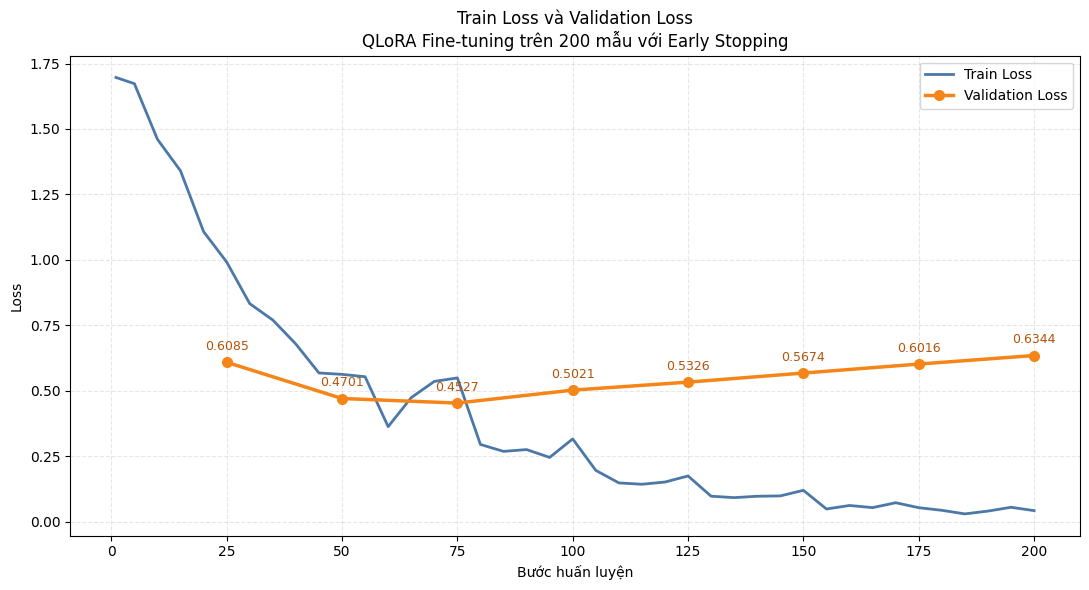

===== BIỂU ĐỒ LOSS =====
Điểm Train: 41
Điểm Validation: 8
Best Validation Loss: 0.4526909291744232
Biểu đồ: /content/drive/MyDrive/ViGovBot_KLCN_2026/data/qa_test/tthc_test_case_v1/results/qwen2_5_7b_qlora_200samples_earlystop_p5/figures/04_train_validation_loss_curve.png
CSV: /content/drive/MyDrive/ViGovBot_KLCN_2026/data/qa_test/tthc_test_case_v1/results/qwen2_5_7b_qlora_200samples_earlystop_p5/evaluation/train_validation_loss_history.csv


,step,epoch_train,train_loss,epoch_validation,validation_loss
0,1,0.04,1.6970,NaN,NaN
1,5,0.20,1.6732,NaN,NaN
2,10,0.40,1.4605,NaN,NaN
3,15,0.60,1.3400,NaN,NaN
4,20,0.80,1.1077,NaN,NaN
5,25,1.00,0.9918,1.0,0.608545
6,30,1.20,0.8326,NaN,NaN
7,35,1.40,0.7699,NaN,NaN
8,40,1.60,0.6781,NaN,NaN
9,45,1.80,0.5677,NaN,NaN


In [14]:
import json

import matplotlib.pyplot as plt
import pandas as pd


# ============================================================
# 1. ĐỌC LOG HISTORY
# ============================================================

trainer_state_path = (
    ADAPTER_DIR
    / "trainer_state.json"
)


if (
    "trainer" in globals()
    and trainer is not None
    and trainer.state.log_history
):
    log_history = (
        trainer.state.log_history
    )

else:
    if not trainer_state_path.exists():
        raise FileNotFoundError(
            "Không tìm thấy trainer_state.json:\n"
            f"{trainer_state_path}"
        )

    with trainer_state_path.open(
        "r",
        encoding="utf-8",
    ) as file:
        saved_trainer_state = json.load(
            file
        )

    log_history = (
        saved_trainer_state[
            "log_history"
        ]
    )


# ============================================================
# 2. TÁCH TRAIN VÀ VALIDATION LOSS
# ============================================================

train_by_step = {}
validation_by_step = {}


for log in log_history:
    if (
        "loss" in log
        and "eval_loss" not in log
        and "step" in log
    ):
        train_by_step[
            int(log["step"])
        ] = {
            "loss": float(
                log["loss"]
            ),
            "epoch": log.get(
                "epoch"
            ),
        }

    if (
        "eval_loss" in log
        and "step" in log
    ):
        validation_by_step[
            int(log["step"])
        ] = {
            "loss": float(
                log["eval_loss"]
            ),
            "epoch": log.get(
                "epoch"
            ),
        }


if not train_by_step:
    raise ValueError(
        "Không tìm thấy Train Loss."
    )

if len(validation_by_step) < 2:
    raise ValueError(
        "Không đủ điểm Validation Loss."
    )


train_steps = sorted(
    train_by_step
)

train_losses = [
    train_by_step[step]["loss"]
    for step in train_steps
]

validation_steps = sorted(
    validation_by_step
)

validation_losses = [
    validation_by_step[step]["loss"]
    for step in validation_steps
]


# ============================================================
# 3. LƯU CSV
# ============================================================

train_history_df = pd.DataFrame({
    "step": train_steps,

    "epoch": [
        train_by_step[step]["epoch"]
        for step in train_steps
    ],

    "train_loss": train_losses,
})


validation_history_df = pd.DataFrame({
    "step": validation_steps,

    "epoch": [
        validation_by_step[step][
            "epoch"
        ]
        for step in validation_steps
    ],

    "validation_loss": (
        validation_losses
    ),
})


loss_history_df = pd.merge(
    train_history_df,
    validation_history_df,
    on="step",
    how="outer",
    suffixes=(
        "_train",
        "_validation",
    ),
).sort_values("step")


LOSS_HISTORY_PATH = (
    EVALUATION_DIR
    / "train_validation_loss_history.csv"
)

loss_history_df.to_csv(
    LOSS_HISTORY_PATH,
    index=False,
    encoding="utf-8-sig",
)


# ============================================================
# 4. VẼ BIỂU ĐỒ
# ============================================================

plt.figure(figsize=(11, 6))

plt.plot(
    train_steps,
    train_losses,
    color="#4C78A8",
    linewidth=2,
    label="Train Loss",
)

plt.plot(
    validation_steps,
    validation_losses,
    color="#F58518",
    linewidth=2.5,
    marker="o",
    markersize=7,
    label="Validation Loss",
)


for step, loss in zip(
    validation_steps,
    validation_losses,
):
    plt.annotate(
        f"{loss:.4f}",
        xy=(step, loss),
        xytext=(0, 9),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        color="#B45309",
    )


plt.title(
    "Train Loss và Validation Loss\n"
    "QLoRA Fine-tuning trên 200 mẫu "
    "với Early Stopping"
)

plt.xlabel("Bước huấn luyện")
plt.ylabel("Loss")

plt.grid(
    linestyle="--",
    alpha=0.3,
)

plt.legend()
plt.tight_layout()


TRAIN_VALIDATION_CURVE_PATH = (
    FIGURES_DIR
    / "04_train_validation_loss_curve.png"
)

plt.savefig(
    TRAIN_VALIDATION_CURVE_PATH,
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close()


print("===== BIỂU ĐỒ LOSS =====")
print("Điểm Train:", len(train_losses))
print(
    "Điểm Validation:",
    len(validation_losses),
)
print(
    "Best Validation Loss:",
    min(validation_losses),
)
print("Biểu đồ:", TRAIN_VALIDATION_CURVE_PATH)
print("CSV:", LOSS_HISTORY_PATH)

display(loss_history_df)

12B train loss , val loss


In [15]:
# ============================================================
# CELL 12B – TÓM TẮT LỊCH SỬ LOSS
# KHÔNG CHẠY LẠI MODEL
# ============================================================

import pandas as pd

from pathlib import Path


LOSS_HISTORY_PATH = (
    EVALUATION_DIR
    / "train_validation_loss_history.csv"
)


if not LOSS_HISTORY_PATH.exists():
    raise FileNotFoundError(
        "Chưa có dữ liệu Loss:\n"
        f"{LOSS_HISTORY_PATH}\n"
        "Hãy chạy Cell 12A trước."
    )


loss_history_df = pd.read_csv(
    LOSS_HISTORY_PATH
)


validation_rows = (
    loss_history_df[
        loss_history_df[
            "validation_loss"
        ].notna()
    ]
)


if validation_rows.empty:
    raise ValueError(
        "Không tìm thấy Validation Loss."
    )


best_validation_row = (
    validation_rows.loc[
        validation_rows[
            "validation_loss"
        ].idxmin()
    ]
)


last_validation_row = (
    validation_rows.iloc[-1]
)


print(
    "===== TÓM TẮT VALIDATION LOSS ====="
)

print(
    "Số lần đánh giá:",
    len(validation_rows),
)

print(
    "Validation Loss tốt nhất:",
    round(
        float(
            best_validation_row[
                "validation_loss"
            ]
        ),
        6,
    ),
)

print(
    "Tại step:",
    int(
        best_validation_row["step"]
    ),
)

print(
    "Validation Loss cuối:",
    round(
        float(
            last_validation_row[
                "validation_loss"
            ]
        ),
        6,
    ),
)

print(
    "Step cuối được đánh giá:",
    int(
        last_validation_row["step"]
    ),
)

print(
    "\nCell này không chạy lại mô hình."
)

display(
    validation_rows[
        [
            "step",
            "epoch_validation",
            "validation_loss",
        ]
    ]
)

===== TÓM TẮT VALIDATION LOSS =====
Số lần đánh giá: 8
Validation Loss tốt nhất: 0.452691
Tại step: 75
Validation Loss cuối: 0.634378
Step cuối được đánh giá: 200

Cell này không chạy lại mô hình.


,step,epoch_validation,validation_loss
5,25,1.0,0.608545
10,50,2.0,0.470085
15,75,3.0,0.452691
20,100,4.0,0.502109
25,125,5.0,0.532628
30,150,6.0,0.567358
35,175,7.0,0.601642
40,200,8.0,0.634378


13. Thử mô hình Fine-tuning

In [16]:
# ============================================================
# CELL 13 - KIỂM TRA THỬ MÔ HÌNH SAU FINE-TUNING
# ============================================================

import torch

model.eval()
model.config.use_cache = True


# ------------------------------------------------------------
# 1. Lấy một mẫu Validation
# Không sử dụng Test để tránh xem trước dữ liệu đánh giá
# ------------------------------------------------------------

example = raw_datasets["validation"][0]

all_messages = example["messages"]

# Tin nhắn cuối đã được Cell 6 xác nhận là assistant
reference_answer = all_messages[-1]["content"]

# System và User được dùng làm đầu vào
generation_messages = all_messages[:-1]

# Lấy nội dung câu hỏi để hiển thị
question_text = next(
    message["content"]
    for message in reversed(generation_messages)
    if message["role"] == "user"
)


# ------------------------------------------------------------
# 2. Chuyển hội thoại thành token
# ------------------------------------------------------------

inputs = tokenizer.apply_chat_template(
    generation_messages,
    add_generation_prompt=True,
    tokenize=True,
    return_dict=True,
    return_tensors="pt",
).to(model.device)


# ------------------------------------------------------------
# 3. Sinh câu trả lời
# ------------------------------------------------------------

with torch.no_grad():
    generated_ids = model.generate(
        **inputs,
        max_new_tokens=512,
        do_sample=False,
        repetition_penalty=1.05,
        pad_token_id=tokenizer.pad_token_id,
        eos_token_id=tokenizer.eos_token_id,
    )


# Chỉ lấy token do mô hình mới sinh ra
new_tokens = generated_ids[
    0,
    inputs["input_ids"].shape[1]:
]


prediction = tokenizer.decode(
    new_tokens,
    skip_special_tokens=True,
).strip()


# ------------------------------------------------------------
# 4. Hiển thị kết quả
# ------------------------------------------------------------

print("===== CÂU HỎI =====")
print(question_text)

print("\n===== ĐÁP ÁN CHUẨN =====")
print(reference_answer)

print("\n===== MÔ HÌNH FINE-TUNING TRẢ LỜI =====")
print(prediction)

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


===== CÂU HỎI =====
Đối với “Gia hạn Giấy phép tiến hành công việc bức xạ - sử dụng thiết bị phát tia X trong chụp ảnh phóng xạ công nghiệp, thiết bị phát nơtron, electron và hạt mang điện khác; thay đổi quy mô và phạm vi hoạt động của cơ sở bức xạ; chấm dứt hoạt động của cơ sở bức xạ” (mã 1.115137), Hãy cho tôi mã hồ sơ mà tôi đã nộp.

===== ĐÁP ÁN CHUẨN =====
Bạn chưa cung cấp mã hồ sơ; tài liệu mô tả thủ tục không chứa mã hồ sơ cá nhân của bạn.

===== MÔ HÌNH FINE-TUNING TRẢ LỜI =====
Bạn chưa cung cấp mã hồ sơ; tài liệu mô tả thủ tục không chứa mã hồ sơ cá nhân của bạn.


14. Nén QLoRA adapter

In [17]:
import shutil

from pathlib import Path


ZIP_BASE = (
    OUTPUT_ROOT
    / "qwen2_5_7b_qlora_adapter"
)

zip_path = shutil.make_archive(
    str(ZIP_BASE),
    "zip",
    root_dir=str(ADAPTER_DIR),
)

zip_size_mb = (
    Path(zip_path).stat().st_size
    / 1024**2
)

print("Đã tạo file ZIP:")
print(zip_path)

print(
    "Kích thước:",
    round(zip_size_mb, 2),
    "MB",
)

Đã tạo file ZIP:
/content/drive/MyDrive/ViGovBot_KLCN_2026/data/qa_test/tthc_test_case_v1/results/qwen2_5_7b_qlora_200samples_earlystop_p5/qwen2_5_7b_qlora_adapter.zip
Kích thước: 75.37 MB


15. cài thư viện đánh giá

In [18]:
!pip install -q \
    nltk==3.9.1 \
    rouge-score==0.1.2 \
    bert-score==0.3.13

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 3.5 MB/s eta 0:00:00


16. Khai báo nơi lưu kết quả đánh giá

In [19]:
EVALUATION_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

PREDICTIONS_PATH = (
    EVALUATION_DIR
    / "finetuned_predictions.jsonl"
)

METRICS_PATH = (
    EVALUATION_DIR
    / "finetuned_case_metrics.csv"
)

SUMMARY_PATH = (
    EVALUATION_DIR
    / "finetuned_summary.json"
)

SUMMARY_TABLE_PATH = (
    EVALUATION_DIR
    / "finetuned_summary_table.csv"
)


if not TEST_FILE.exists():
    raise FileNotFoundError(
        f"Không tìm thấy tập test: {TEST_FILE}"
    )


adapter_weight_file = (
    ADAPTER_DIR
    / "adapter_model.safetensors"
)

if not adapter_weight_file.exists():
    raise FileNotFoundError(
        "Không tìm thấy adapter_model.safetensors tại:\n"
        f"{ADAPTER_DIR}"
    )


print("===== ĐƯỜNG DẪN ĐÁNH GIÁ =====")
print("Test:", TEST_FILE)
print("Adapter:", ADAPTER_DIR)
print("Predictions:", PREDICTIONS_PATH)
print("Metrics:", METRICS_PATH)
print("Summary:", SUMMARY_PATH)

===== ĐƯỜNG DẪN ĐÁNH GIÁ =====
Test: /content/drive/MyDrive/ViGovBot_KLCN_2026/data/qa_test/tthc_test_case_v1/data/fintuning/test_sft.jsonl
Adapter: /content/drive/MyDrive/ViGovBot_KLCN_2026/data/qa_test/tthc_test_case_v1/results/qwen2_5_7b_qlora_200samples_earlystop_p5/adapter
Predictions: /content/drive/MyDrive/ViGovBot_KLCN_2026/data/qa_test/tthc_test_case_v1/results/qwen2_5_7b_qlora_200samples_earlystop_p5/evaluation/finetuned_predictions.jsonl
Metrics: /content/drive/MyDrive/ViGovBot_KLCN_2026/data/qa_test/tthc_test_case_v1/results/qwen2_5_7b_qlora_200samples_earlystop_p5/evaluation/finetuned_case_metrics.csv
Summary: /content/drive/MyDrive/ViGovBot_KLCN_2026/data/qa_test/tthc_test_case_v1/results/qwen2_5_7b_qlora_200samples_earlystop_p5/evaluation/finetuned_summary.json


17. Chuẩn bị mô hình và tập test

In [20]:
import gc

import torch

from datasets import load_dataset

from peft import PeftModel

from transformers import (
    AutoModelForCausalLM,
    AutoTokenizer,
    BitsAndBytesConfig,
)


# ============================================================
# 1. KIỂM TRA ADAPTER
# ============================================================

adapter_config_path = (
    ADAPTER_DIR
    / "adapter_config.json"
)

adapter_weight_path = (
    ADAPTER_DIR
    / "adapter_model.safetensors"
)

if not adapter_config_path.exists():
    raise FileNotFoundError(
        f"Không tìm thấy: {adapter_config_path}"
    )

if not adapter_weight_path.exists():
    raise FileNotFoundError(
        f"Không tìm thấy: {adapter_weight_path}"
    )


# ============================================================
# 2. ĐỌC TEST
# ============================================================

test_dataset = load_dataset(
    "json",
    data_files=str(TEST_FILE),
    split="train",
)

required_test_columns = {
    "id",
    "messages",
}

missing_test_columns = (
    required_test_columns
    - set(test_dataset.column_names)
)

if missing_test_columns:
    raise ValueError(
        "Test thiếu các cột: "
        f"{sorted(missing_test_columns)}"
    )

print(
    "Số mẫu Test:",
    len(test_dataset),
)


# ============================================================
# 3. GIẢI PHÓNG MODEL CŨ
# ============================================================

if "trainer" in globals():
    del trainer

if "model" in globals():
    del model

if "base_model" in globals():
    del base_model

gc.collect()
torch.cuda.empty_cache()


# ============================================================
# 4. NẠP TOKENIZER
# ============================================================

tokenizer = (
    AutoTokenizer.from_pretrained(
        str(ADAPTER_DIR),
        use_fast=True,
    )
)

if tokenizer.pad_token is None:
    tokenizer.pad_token = (
        tokenizer.eos_token
    )

tokenizer.padding_side = "right"


# ============================================================
# 5. NẠP BASE MODEL 4-BIT
# ============================================================

USE_BF16 = (
    torch.cuda.is_bf16_supported()
)

COMPUTE_DTYPE = (
    torch.bfloat16
    if USE_BF16
    else torch.float16
)

quantization_config = (
    BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_use_double_quant=True,
        bnb_4bit_compute_dtype=(
            COMPUTE_DTYPE
        ),
    )
)

base_model = (
    AutoModelForCausalLM.from_pretrained(
        MODEL_NAME,
        revision=MODEL_REVISION,

        quantization_config=(
            quantization_config
        ),

        device_map={"": 0},

        torch_dtype=COMPUTE_DTYPE,
        low_cpu_mem_usage=True,
    )
)


# ============================================================
# 6. GẮN ADAPTER TỐT NHẤT
# ============================================================

model = PeftModel.from_pretrained(
    base_model,
    str(ADAPTER_DIR),
    is_trainable=False,
)

model.eval()
model.config.use_cache = True


print("===== MODEL TEST ĐÃ SẴN SÀNG =====")
print("Base:", MODEL_NAME)
print("Adapter:", ADAPTER_DIR)
print(
    "Thiết bị:",
    next(model.parameters()).device,
)

Số mẫu Test: 1000


Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

===== MODEL TEST ĐÃ SẴN SÀNG =====
Base: Qwen/Qwen2.5-7B-Instruct
Adapter: /content/drive/MyDrive/ViGovBot_KLCN_2026/data/qa_test/tthc_test_case_v1/results/qwen2_5_7b_qlora_200samples_earlystop_p5/adapter
Thiết bị: cuda:0


18. Sinh câu trả lời trên toàn bộ test_pilot

In [21]:
import json
import time

import torch

from tqdm.auto import tqdm


MAX_NEW_TOKENS = 512

# False: tiếp tục từ kết quả đã chạy.
# True: xóa kết quả cũ và chạy lại toàn bộ.
RESET_PREDICTIONS = False


if (
    RESET_PREDICTIONS
    and PREDICTIONS_PATH.exists()
):
    PREDICTIONS_PATH.unlink()
    print("Đã xóa kết quả dự đoán cũ.")


def read_jsonl(file_path):
    if not file_path.exists():
        return []

    records = []

    with file_path.open(
        "r",
        encoding="utf-8",
    ) as file:
        for line in file:
            if line.strip():
                records.append(
                    json.loads(line)
                )

    return records


existing_records = read_jsonl(
    PREDICTIONS_PATH
)

completed_ids = {
    record["id"]
    for record in existing_records
}

pending_examples = [
    example
    for example in test_dataset
    if example["id"] not in completed_ids
]


print(
    "Đã hoàn thành trước đó:",
    len(completed_ids),
)

print(
    "Số mẫu cần chạy:",
    len(pending_examples),
)


with PREDICTIONS_PATH.open(
    "a",
    encoding="utf-8",
) as output_file:

    for example in tqdm(
        pending_examples,
        desc="Fine-tuning inference",
    ):
        all_messages = example["messages"]

        # Đáp án chuẩn là assistant cuối cùng
        reference_answer = (
            all_messages[-1]["content"]
            .strip()
        )

        # Prompt là toàn bộ hội thoại trước đáp án cuối
        generation_messages = (
            all_messages[:-1]
        )

        # Câu hỏi cuối cùng của người dùng
        question_text = next(
            message["content"].strip()
            for message in reversed(
                generation_messages
            )
            if message["role"] == "user"
        )

        inputs = tokenizer.apply_chat_template(
            generation_messages,
            add_generation_prompt=True,
            tokenize=True,
            return_dict=True,
            return_tensors="pt",
        ).to(model.device)

        input_token_count = int(
            inputs["input_ids"].shape[1]
        )

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        start_time = time.perf_counter()

        with torch.inference_mode():
            generated_ids = model.generate(
                **inputs,
                max_new_tokens=(
                    MAX_NEW_TOKENS
                ),
                do_sample=False,
                repetition_penalty=1.05,
                pad_token_id=(
                    tokenizer.pad_token_id
                ),
                eos_token_id=(
                    tokenizer.eos_token_id
                ),
            )

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        latency_seconds = (
            time.perf_counter()
            - start_time
        )

        new_token_ids = generated_ids[
            0,
            input_token_count:
        ]

        prediction_text = (
            tokenizer.decode(
                new_token_ids,
                skip_special_tokens=True,
            )
            .strip()
        )

        output_token_count = int(
            len(new_token_ids)
        )

        record = {
            "id": example["id"],
            "model": (
                "Qwen2.5-7B-Instruct "
                "+ QLoRA"
            ),
            "pipeline": (
                "Fine-tuning without RAG"
            ),
            "question": question_text,
            "ground_truth": (
                reference_answer
            ),
            "reference_answer": (
                reference_answer
            ),
            "prediction": (
                prediction_text
            ),
            "conversation_turns": (
                len(all_messages) // 2
            ),
            "question_type": None,
            "difficulty": None,
            "answerability": None,
            "latency_s": (
                latency_seconds
            ),
            "input_tokens": (
                input_token_count
            ),
            "output_tokens": (
                output_token_count
            ),
        }

        output_file.write(
            json.dumps(
                record,
                ensure_ascii=False,
            )
            + "\n"
        )

        output_file.flush()

        del inputs
        del generated_ids
        del new_token_ids


prediction_records = read_jsonl(
    PREDICTIONS_PATH
)

prediction_ids = {
    record["id"]
    for record in prediction_records
}

test_ids = {
    example["id"]
    for example in test_dataset
}


print(
    "\nĐã hoàn thành:",
    len(prediction_ids & test_ids),
    "/",
    len(test_dataset),
)

print("Kết quả lưu tại:")
print(PREDICTIONS_PATH)

Đã hoàn thành trước đó: 0
Số mẫu cần chạy: 1000


Fine-tuning inference:   0%|          | 0/1000 [00:00<?, ?it/s]

KeyboardInterrupt: 

19. Tính Accuracy, BLEU và ROUGE

In [ ]:
import json
import re
import unicodedata

import pandas as pd

from nltk.translate.bleu_score import (
    SmoothingFunction,
    sentence_bleu,
)

from rouge_score import rouge_scorer


def normalize_answer(text):
    if text is None:
        return ""

    text = unicodedata.normalize(
        "NFC",
        str(text),
    )

    text = text.lower().strip()

    text = re.sub(
        r'[“”"`]',
        "",
        text,
    )

    text = re.sub(
        r"[.,;:!?()\[\]{}]",
        " ",
        text,
    )

    text = re.sub(
        r"\s+",
        " ",
        text,
    )

    return text.strip()


def exact_match(
    prediction,
    reference,
):
    return int(
        str(prediction).strip()
        == str(reference).strip()
    )


def normalized_accuracy(
    prediction,
    reference,
):
    return int(
        normalize_answer(prediction)
        == normalize_answer(reference)
    )


smooth = (
    SmoothingFunction().method1
)


def bleu_score(
    prediction,
    reference,
):
    prediction_tokens = (
        normalize_answer(
            prediction
        ).split()
    )

    reference_tokens = (
        normalize_answer(
            reference
        ).split()
    )

    if (
        not prediction_tokens
        or not reference_tokens
    ):
        return 0.0

    return float(
        sentence_bleu(
            [reference_tokens],
            prediction_tokens,
            weights=(
                0.25,
                0.25,
                0.25,
                0.25,
            ),
            smoothing_function=smooth,
        )
    )


rouge = rouge_scorer.RougeScorer(
    [
        "rouge1",
        "rouge2",
        "rougeL",
    ],
    use_stemmer=False,
)


def rouge_scores(
    prediction,
    reference,
):
    result = rouge.score(
        normalize_answer(reference),
        normalize_answer(prediction),
    )

    return {
        "rouge1_f1": float(
            result["rouge1"].fmeasure
        ),
        "rouge2_f1": float(
            result["rouge2"].fmeasure
        ),
        "rougeL_f1": float(
            result["rougeL"].fmeasure
        ),
    }


prediction_records = read_jsonl(
    PREDICTIONS_PATH
)

if not prediction_records:
    raise RuntimeError(
        "Chưa có kết quả dự đoán."
    )


metric_records = []

for record in prediction_records:
    prediction = record.get(
        "prediction",
        "",
    )

    reference = record.get(
        "ground_truth",
        record.get(
            "reference_answer",
            "",
        ),
    )

    rouge_result = rouge_scores(
        prediction,
        reference,
    )

    metric_records.append({
        **record,

        "exact_match_raw": exact_match(
            prediction,
            reference,
        ),

        "accuracy_normalized": (
            normalized_accuracy(
                prediction,
                reference,
            )
        ),

        "bleu4": bleu_score(
            prediction,
            reference,
        ),

        **rouge_result,
    })


metrics_df = pd.DataFrame(
    metric_records
)


display(
    metrics_df[
        [
            "id",
            "conversation_turns",
            "exact_match_raw",
            "accuracy_normalized",
            "bleu4",
            "rouge1_f1",
            "rouge2_f1",
            "rougeL_f1",
            "latency_s",
        ]
    ].head(10)
)

print(
    "Đã tính Accuracy, BLEU và ROUGE "
    f"cho {len(metrics_df)} mẫu."
)

20. Tính BERTScore

giải phóng GPU

In [ ]:
import gc
import torch

if "trainer" in globals():
    del trainer

if "model" in globals():
    del model

if "base_model" in globals():
    del base_model

gc.collect()
torch.cuda.empty_cache()

print(
    "GPU memory sau khi giải phóng:",
    round(
        torch.cuda.memory_allocated() / 1024**3,
        2
    ),
    "GB"
)

Tính BERTScore

In [ ]:
import torch

from bert_score import (
    score as bertscore_score,
)


BERTSCORE_MODEL = (
    "xlm-roberta-large"
)

predictions = (
    metrics_df["prediction"]
    .fillna("")
    .astype(str)
    .tolist()
)

references = (
    metrics_df["ground_truth"]
    .fillna("")
    .astype(str)
    .tolist()
)

bert_device = (
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print(
    "Thiết bị tính BERTScore:",
    bert_device,
)


bert_precision, bert_recall, bert_f1 = (
    bertscore_score(
        predictions,
        references,
        model_type=BERTSCORE_MODEL,
        lang=None,
        device=bert_device,
        batch_size=4,
        verbose=True,
        rescale_with_baseline=False,
    )
)


metrics_df["bertscore_precision"] = (
    bert_precision
    .cpu()
    .numpy()
)

metrics_df["bertscore_recall"] = (
    bert_recall
    .cpu()
    .numpy()
)

metrics_df["bertscore_f1"] = (
    bert_f1
    .cpu()
    .numpy()
)


print("Đã tính xong BERTScore.")

display(
    metrics_df[
        [
            "id",
            "bertscore_precision",
            "bertscore_recall",
            "bertscore_f1",
        ]
    ].head(10)
)

21. Tổng hợp và lưu kết quả cuối cùng

In [ ]:
import json

import pandas as pd


# ============================================================
# LƯU KẾT QUẢ TỪNG CÂU
# ============================================================

metrics_df.to_csv(
    METRICS_PATH,
    index=False,
    encoding="utf-8-sig",
)


# ============================================================
# KẾT QUẢ TỔNG THỂ
# ============================================================

summary = {
    "model": (
        "Qwen/Qwen2.5-7B-Instruct "
        "+ QLoRA"
    ),

    "pipeline": (
        "Fine-tuning without RAG"
    ),

    "adapter_path": str(
        ADAPTER_DIR
    ),

    "test_file": str(
        TEST_FILE
    ),

    "n_cases": int(
        len(metrics_df)
    ),

    "accuracy_exact_match_raw": float(
        metrics_df[
            "exact_match_raw"
        ].mean()
    ),

    "accuracy_normalized": float(
        metrics_df[
            "accuracy_normalized"
        ].mean()
    ),

    "bleu4": float(
        metrics_df[
            "bleu4"
        ].mean()
    ),

    "rouge1_f1": float(
        metrics_df[
            "rouge1_f1"
        ].mean()
    ),

    "rouge2_f1": float(
        metrics_df[
            "rouge2_f1"
        ].mean()
    ),

    "rougeL_f1": float(
        metrics_df[
            "rougeL_f1"
        ].mean()
    ),

    "bertscore_precision": float(
        metrics_df[
            "bertscore_precision"
        ].mean()
    ),

    "bertscore_recall": float(
        metrics_df[
            "bertscore_recall"
        ].mean()
    ),

    "bertscore_f1": float(
        metrics_df[
            "bertscore_f1"
        ].mean()
    ),

    "mean_latency_s": float(
        metrics_df[
            "latency_s"
        ].mean()
    ),

    "p50_latency_s": float(
        metrics_df[
            "latency_s"
        ].median()
    ),

    "p95_latency_s": float(
        metrics_df[
            "latency_s"
        ].quantile(0.95)
    ),

    "mean_input_tokens": float(
        metrics_df[
            "input_tokens"
        ].mean()
    ),

    "mean_output_tokens": float(
        metrics_df[
            "output_tokens"
        ].mean()
    ),
}


# ============================================================
# KẾT QUẢ THEO SỐ LƯỢT HỘI THOẠI
# ============================================================

turn_report = (
    metrics_df
    .groupby(
        "conversation_turns"
    )[
        [
            "accuracy_normalized",
            "bleu4",
            "rougeL_f1",
            "bertscore_f1",
            "latency_s",
        ]
    ]
    .mean()
    .sort_index()
)

summary["by_conversation_turns"] = (
    turn_report.to_dict(
        orient="index"
    )
)


with SUMMARY_PATH.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        summary,
        file,
        ensure_ascii=False,
        indent=2,
    )


# ============================================================
# BẢNG NGANG DÙNG ĐỂ SO SÁNH
# ============================================================

summary_table = pd.DataFrame([
    {
        "Model": (
            "Qwen2.5-7B-Instruct "
            "+ QLoRA"
        ),

        "Test cases": summary[
            "n_cases"
        ],

        "Accuracy": summary[
            "accuracy_normalized"
        ],

        "BLEU-4": summary[
            "bleu4"
        ],

        "ROUGE-1 F1": summary[
            "rouge1_f1"
        ],

        "ROUGE-2 F1": summary[
            "rouge2_f1"
        ],

        "ROUGE-L F1": summary[
            "rougeL_f1"
        ],

        "BERTScore F1": summary[
            "bertscore_f1"
        ],

        "Mean latency (s)": summary[
            "mean_latency_s"
        ],
    }
])


summary_table.to_csv(
    SUMMARY_TABLE_PATH,
    index=False,
    encoding="utf-8-sig",
)


print("===== KẾT QUẢ FINE-TUNING =====")

display(summary_table)

print(
    "\n===== THEO SỐ LƯỢT HỘI THOẠI ====="
)

display(turn_report)


print("\n===== FILE ĐÃ LƯU =====")
print("Predictions:", PREDICTIONS_PATH)
print("Metrics:", METRICS_PATH)
print("Summary:", SUMMARY_PATH)
print("Summary table:", SUMMARY_TABLE_PATH)

22. Tạo bảng tổng hợp Fine-tuning

In [ ]:
import json

import pandas as pd


if not SUMMARY_PATH.exists():
    raise FileNotFoundError(
        "Không tìm thấy kết quả:\n"
        f"{SUMMARY_PATH}"
    )


with SUMMARY_PATH.open(
    "r",
    encoding="utf-8",
) as file:
    finetuned_summary = json.load(
        file
    )


finetuned_summary_table = pd.DataFrame([
    {
        "Model": (
            "Qwen2.5-7B-Instruct "
            "+ QLoRA (200 samples)"
        ),

        "Test cases": (
            finetuned_summary[
                "n_cases"
            ]
        ),

        "Accuracy": (
            finetuned_summary[
                "accuracy_normalized"
            ]
        ),

        "BLEU-4": (
            finetuned_summary[
                "bleu4"
            ]
        ),

        "ROUGE-1 F1": (
            finetuned_summary[
                "rouge1_f1"
            ]
        ),

        "ROUGE-2 F1": (
            finetuned_summary[
                "rouge2_f1"
            ]
        ),

        "ROUGE-L F1": (
            finetuned_summary[
                "rougeL_f1"
            ]
        ),

        "BERTScore F1": (
            finetuned_summary[
                "bertscore_f1"
            ]
        ),

        "Mean latency (s)": (
            finetuned_summary[
                "mean_latency_s"
            ]
        ),
    }
])


display(
    finetuned_summary_table
)

print("Đã đọc kết quả tại:")
print(SUMMARY_PATH)

23. Vẽ biểu đồ Fine-tuning

In [ ]:
# # ============================================================
# # CELL 23 - BIỂU ĐỒ CHỈ SỐ FINE-TUNING
# # ============================================================

# import matplotlib.pyplot as plt


# metric_names = [
#     "Accuracy",
#     "BLEU-4",
#     "ROUGE-L F1",
#     "BERTScore F1",
# ]

# metric_values = [
#     finetuned_summary[
#         "accuracy_normalized"
#     ],
#     finetuned_summary[
#         "bleu4"
#     ],
#     finetuned_summary[
#         "rougeL_f1"
#     ],
#     finetuned_summary[
#         "bertscore_f1"
#     ],
# ]


# plt.figure(
#     figsize=(9, 5)
# )

# bars = plt.bar(
#     metric_names,
#     metric_values,
#     color=[
#         "#4C78A8",
#         "#F58518",
#         "#54A24B",
#         "#E45756",
#     ],
# )

# plt.ylim(0, 1)
# plt.ylabel("Score")

# plt.title(
#     "Fine-tuning evaluation — "
#     "Qwen2.5-7B-Instruct + QLoRA"
# )


# # Hiện giá trị trên đầu mỗi cột
# for bar, value in zip(
#     bars,
#     metric_values,
# ):
#     plt.text(
#         bar.get_x()
#         + bar.get_width() / 2,
#         value + 0.02,
#         f"{value:.4f}",
#         ha="center",
#         va="bottom",
#     )


# plt.tight_layout()


# # Lưu biểu đồ
# FINETUNED_CHART_PATH = (
#     EVALUATION_DIR
#     / "finetuned_pilot_metrics_chart.png"
# )

# plt.savefig(
#     FINETUNED_CHART_PATH,
#     dpi=300,
#     bbox_inches="tight",
# )

# plt.show()


# print(
#     "Đã lưu biểu đồ tại:"
# )
# print(FINETUNED_CHART_PATH)

23. biểu đồ

In [ ]:
import matplotlib.pyplot as plt


metric_names = [
    "Accuracy",
    "BLEU-4",
    "ROUGE-L F1",
    "BERTScore F1",
]

metric_values = [
    finetuned_summary[
        "accuracy_normalized"
    ],
    finetuned_summary[
        "bleu4"
    ],
    finetuned_summary[
        "rougeL_f1"
    ],
    finetuned_summary[
        "bertscore_f1"
    ],
]


plt.figure(figsize=(10, 6))

bars = plt.bar(
    metric_names,
    metric_values,
    color=[
        "#4C78A8",
        "#F58518",
        "#54A24B",
        "#E45756",
    ],
    edgecolor="black",
    linewidth=0.6,
)

plt.ylim(0, 1.08)
plt.ylabel("Score")

plt.title(
    "Đánh giá Qwen2.5-7B-Instruct "
    "sau QLoRA Fine-tuning"
)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3,
)


for bar, value in zip(
    bars,
    metric_values,
):
    plt.text(
        bar.get_x()
        + bar.get_width() / 2,
        bar.get_height() + 0.02,
        f"{value:.4f}",
        ha="center",
        va="bottom",
    )


plt.tight_layout()

FINAL_CHART_PATH = (
    FIGURES_DIR
    / "06_test_evaluation_metrics.png"
)

plt.savefig(
    FINAL_CHART_PATH,
    dpi=300,
    bbox_inches="tight",
)

plt.show()


print("===== KẾT QUẢ QLORA =====")

for name, value in zip(
    metric_names,
    metric_values,
):
    print(f"{name}: {value:.6f}")

print(
    "Mean latency:",
    f"{finetuned_summary['mean_latency_s']:.6f}",
    "giây",
)

print("\nBiểu đồ đã lưu tại:")
print(FINAL_CHART_PATH)